<a href="https://colab.research.google.com/github/dhavltharkaaar/Yolo_Object_Detection/blob/main/yolov5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Sun Jun 22 07:35:53 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# prompt: mount gdrive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!find /content/drive/MyDrive/ -name "Basketball.zip"

/content/drive/MyDrive/Basketball.zip


In [ ]:
!unzip /content/drive/MyDrive/Basketball.zip -d /content/Basketball/

Archive:  /content/drive/MyDrive/Basketball.zip
   creating: /content/Basketball/Basketball/
  inflating: /content/Basketball/Basketball/Basketball (1).jpg  
  inflating: /content/Basketball/Basketball/Basketball (1).txt  
  inflating: /content/Basketball/Basketball/Basketball (10).jpg  
  inflating: /content/Basketball/Basketball/Basketball (10).txt  
  inflating: /content/Basketball/Basketball/Basketball (100).jpg  
  inflating: /content/Basketball/Basketball/Basketball (100).txt  
  inflating: /content/Basketball/Basketball/Basketball (101).jpg  
  inflating: /content/Basketball/Basketball/Basketball (101).txt  
  inflating: /content/Basketball/Basketball/Basketball (102).jpg  
  inflating: /content/Basketball/Basketball/Basketball (102).txt  
  inflating: /content/Basketball/Basketball/Basketball (103).jpg  
  inflating: /content/Basketball/Basketball/Basketball (103).txt  
  inflating: /content/Basketball/Basketball/Basketball (104).jpg  
  inflating: /content/Basketball/Basketbal

In [ ]:
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -r requirements.txt

Cloning into 'yolov5'...
remote: Enumerating objects: 17496, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 17496 (delta 2), reused 0 (delta 0), pack-reused 17490 (from 3)
Receiving objects: 100% (17496/17496), 16.56 MiB | 29.18 MiB/s, done.
Resolving deltas: 100% (11997/11997), done.
/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.2 MB/s eta 0:00

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Define the base directory
base_dir = '/content/Basketball/Basketball'

# List image files (supporting .jpg, .jpeg, and .png extensions)
images = [f for f in os.listdir(base_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]

# Ensure that labels have corresponding .txt files
labels = [f.replace('.jpg', '.txt').replace('.jpeg', '.txt').replace('.png', '.txt') for f in images]

# Check that there are images and labels
if len(images) == 0 or len(labels) == 0:
    raise ValueError("No images or labels found in the specified directory. Please check the file extensions or naming convention.")

# Split data into training and validation (80% train, 20% validation)
train_images, val_images = train_test_split(images, test_size=0.2, random_state=42)

# Create necessary directories for training and validation sets
os.makedirs(os.path.join(base_dir, 'train/images'), exist_ok=True)
os.makedirs(os.path.join(base_dir, 'val/images'), exist_ok=True)
os.makedirs(os.path.join(base_dir, 'train/labels'), exist_ok=True)
os.makedirs(os.path.join(base_dir, 'val/labels'), exist_ok=True)

# Move training images and their corresponding labels
for image in train_images:
    shutil.move(os.path.join(base_dir, image), os.path.join(base_dir, 'train/images', image))
    shutil.move(os.path.join(base_dir, image.replace('.jpg', '.txt').replace('.jpeg', '.txt').replace('.png', '.txt')),
                os.path.join(base_dir, 'train/labels', image.replace('.jpg', '.txt').replace('.jpeg', '.txt').replace('.png', '.txt')))

# Move validation images and their corresponding labels
for image in val_images:
    shutil.move(os.path.join(base_dir, image), os.path.join(base_dir, 'val/images', image))
    shutil.move(os.path.join(base_dir, image.replace('.jpg', '.txt').replace('.jpeg', '.txt').replace('.png', '.txt')),
                os.path.join(base_dir, 'val/labels', image.replace('.jpg', '.txt').replace('.jpeg', '.txt').replace('.png', '.txt')))

# Print how many images were moved into train and validation sets
print(f"Training set: {len(train_images)} images")
print(f"Validation set: {len(val_images)} images")

Training set: 480 images
Validation set: 120 images


In [ ]:
!pip install -U torch torchvision
!pip install -U yolov5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 821.2/821.2 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 97.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.8/156.8 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201

In [ ]:
!git clone https://github.com/ultralytics/yolov5.git
%cd yolov5
!pip install -r requirements.txt

fatal: destination path 'yolov5' already exists and is not an empty directory.
/content/yolov5/yolov5


In [ ]:
# Content of the updated YAML file for 3 classes
yaml_content = """
train: /content/Basketball/Basketball/train/images
val: /content/Basketball/Basketball/val/images

nc: 3  # Number of classes
names: ['Basket', 'Basketball', 'Player']  # List of class names
"""

# Save the updated YAML content to a file
with open('/content/Basketball/Basketball/basketball.yaml', 'w') as f:
    f.write(yaml_content)

print("basketball.yaml file created with 3 classes!")

basketball.yaml file created with 3 classes!


In [ ]:
# Training Yolov5
!python train.py --img 640 --batch 16 --epochs 50 --data /content/Basketball/Basketball/basketball.yaml --weights yolov5s.pt --cache

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
wandb: WARNING ⚠️ wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
2025-06-22 07:54:19.805432: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750578860.113508    2353 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750578860.194725    2353 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS wh

In [ ]:
#Evaluate the Model
!python val.py --weights runs/train/exp/weights/best.pt --data /content/Basketball/Basketball/basketball.yaml --img 640 --iou 0.5

val: data=/content/Basketball/Basketball/basketball.yaml, weights=['runs/train/exp/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.5, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-421-g79c4c31d Python-3.11.11 torch-2.7.1+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7018216 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/Basketball/Basketball/val/labels.cache... 120 images, 0 backgrounds, 0 corrupt: 100% 120/120 [00:00<?, ?it/s]
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% 4/4 [00:05<00:00,  1.40s/it]
                   all        120        584      0.966      0.964      0.978      0.602
                Basket        120         72      0.964      0.972      0.973      0.62

In [ ]:
!python detect.py --weights runs/train/exp/weights/best.pt --img 640 --source "/content/Basketball/Basketball/val/images/Basketball (113).jpg" --save-txt --view-img

detect: weights=['runs/train/exp/weights/best.pt'], source=/content/Basketball/Basketball/val/images/Basketball (113).jpg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=True, save_txt=True, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-421-g79c4c31d Python-3.11.11 torch-2.7.1+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7018216 parameters, 0 gradients, 15.8 GFLOPs
qt.qpa.xcb: could not connect to display 
qt.qpa.plugin: Could not load the Qt platform plugin "xcb" in "/usr/local/lib/python3.11/dist-packages/cv2/qt/plugins" even though it was found.
This application failed to start because no Qt platform plugin could be initialized. R

In [ ]:
!ls /content/yolov5/runs/train/exp

confusion_matrix.png				    PR_curve.png	   val_batch0_pred.jpg
events.out.tfevents.1750578896.87a5b5998bdb.2353.0  R_curve.png		   val_batch1_labels.jpg
F1_curve.png					    results.csv		   val_batch1_pred.jpg
hyp.yaml					    results.png		   val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch0.jpg	   val_batch2_pred.jpg
labels.jpg					    train_batch1.jpg	   weights
opt.yaml					    train_batch2.jpg
P_curve.png					    val_batch0_labels.jpg


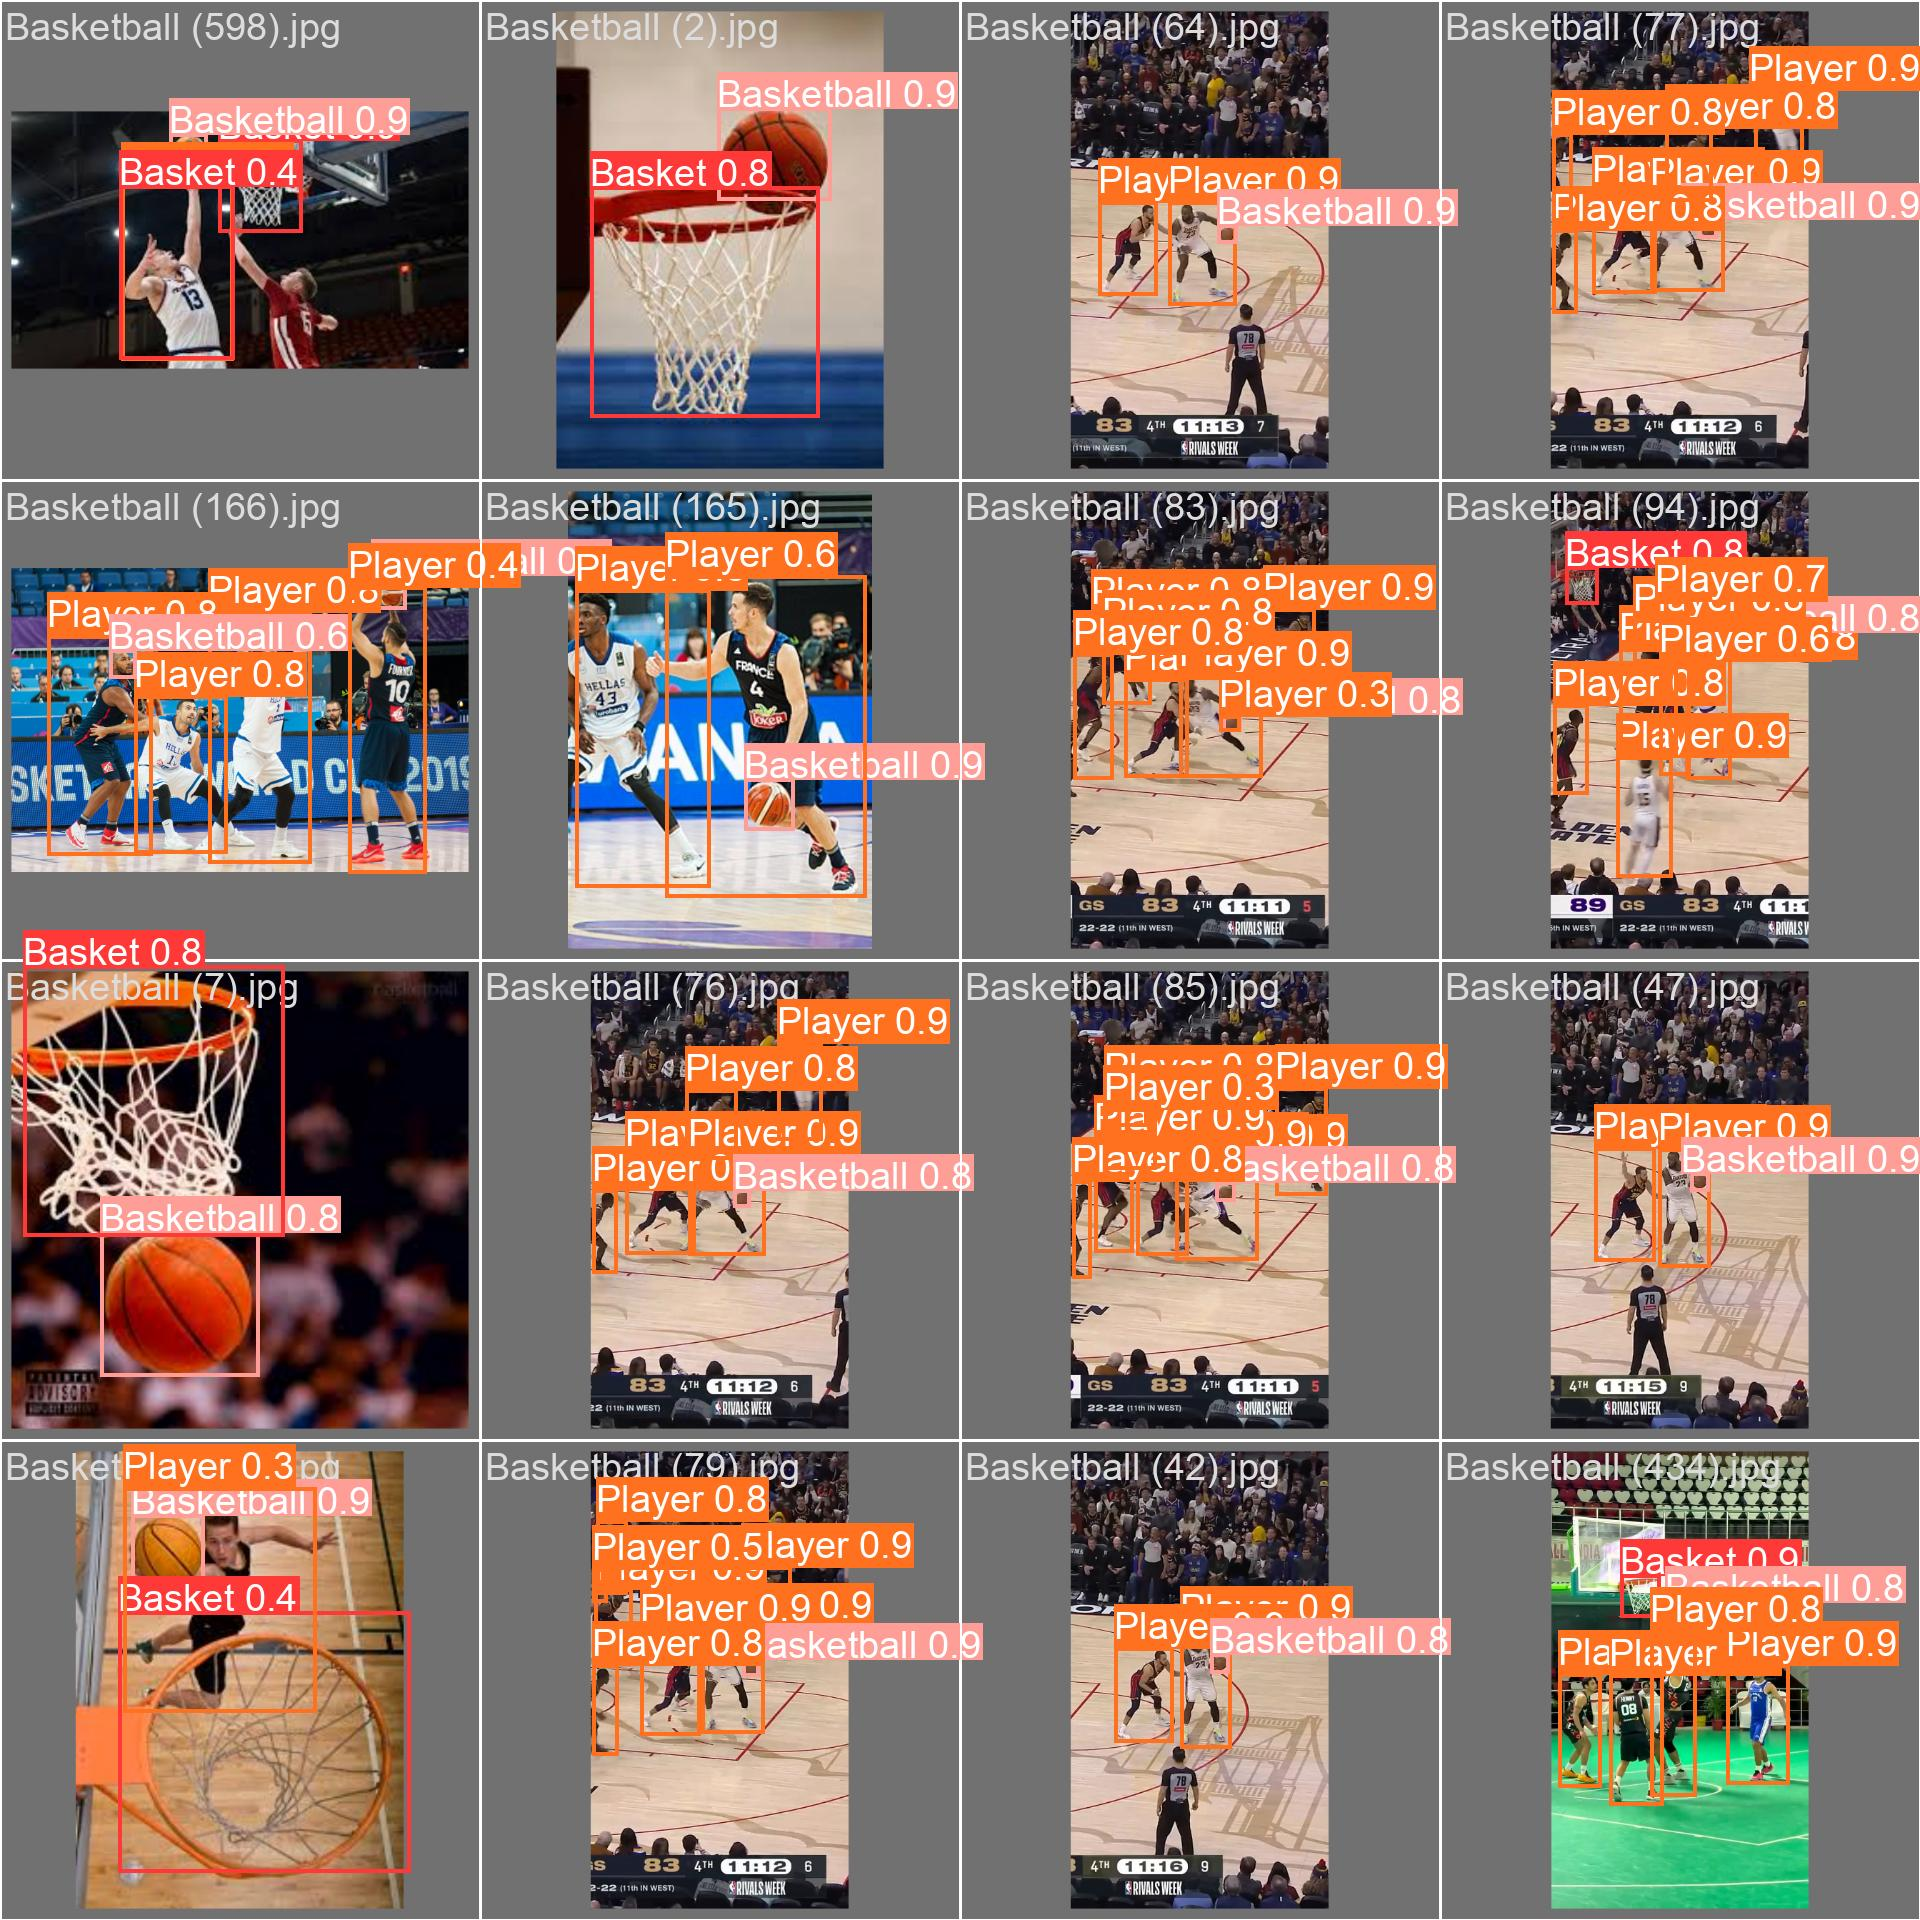

In [ ]:
from IPython.display import Image

# Display the predicted result
Image(filename='/content/yolov5/runs/train/exp/val_batch0_pred.jpg')

In [ ]:
# Predict Unseen data

In [ ]:
!python /content/yolov5/detect.py --weights /content/yolov5/runs/train/exp/weights/best.pt --img 640 --source "/content/drive/MyDrive/Test/images.jpg" --save-txt --view-img

detect: weights=['/content/yolov5/runs/train/exp/weights/best.pt'], source=/content/drive/MyDrive/Test/images.jpg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=True, save_txt=True, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-421-g79c4c31d Python-3.11.11 torch-2.7.1+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7018216 parameters, 0 gradients, 15.8 GFLOPs
qt.qpa.xcb: could not connect to display 
qt.qpa.plugin: Could not load the Qt platform plugin "xcb" in "/usr/local/lib/python3.11/dist-packages/cv2/qt/plugins" even though it was found.
This application failed to start because no Qt platform plugin could be initialized. Reinstall

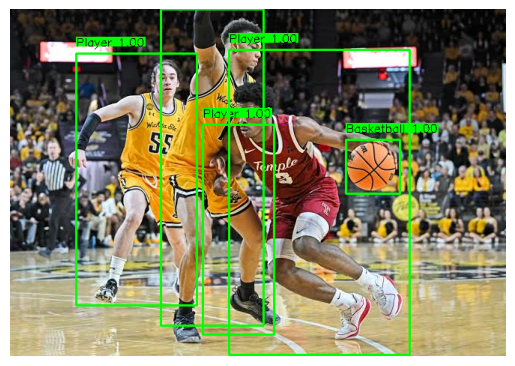

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml

# Path to the image and label file
image_path = '/content/drive/MyDrive/Test/images.jpg'
label_path = '/content/yolov5/runs/detect/exp6/labels/images.txt'
yaml_path = '/content/Basketball/Basketball/basketball.yaml'

# Load class names from the YAML file
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

class_names = data['names']  # This should give you the list of class names

# Read the image using OpenCV
img = cv2.imread(image_path)

# Get image dimensions
height, width, _ = img.shape

# Open the label file and read the detection results
with open(label_path, 'r') as f:
    lines = f.readlines()

# Iterate through each detection and draw the bounding box with labels
for line in lines:
    # Parse the label file: class_id, x_center, y_center, width, height, confidence (optional)
    parts = line.strip().split()

    # Ensure there are at least 5 values (class_id, x_center, y_center, width, height)
    if len(parts) < 5:
        continue  # Skip lines that do not have enough data

    class_id = int(parts[0])
    x_center = float(parts[1]) * width  # Convert normalized x_center to pixels
    y_center = float(parts[2]) * height  # Convert normalized y_center to pixels
    box_width = float(parts[3]) * width  # Convert normalized width to pixels
    box_height = float(parts[4]) * height  # Convert normalized height to pixels

    # Check if confidence is available (optional)
    confidence = float(parts[5]) if len(parts) > 5 else 1.0  # Default confidence = 1.0

    # Convert center coordinates and box dimensions to top-left corner coordinates
    x1 = int(x_center - box_width / 2)
    y1 = int(y_center - box_height / 2)
    x2 = int(x_center + box_width / 2)
    y2 = int(y_center + box_height / 2)

    # Draw the bounding box on the image
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)  # Green box

    # Get the class name and create the label
    label = f"{class_names[class_id]} {confidence:.2f}"

    # Set the font and size for the label text
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.5
    font_thickness = 1
    text_size = cv2.getTextSize(label, font, font_scale, font_thickness)[0]
    text_x = x1
    text_y = y1 - 10  # Place the label just above the box

    # Draw the label background and text
    cv2.rectangle(img, (text_x, text_y), (text_x + text_size[0], text_y - text_size[1]), (0, 255, 0), -1)
    cv2.putText(img, label, (text_x, text_y), font, font_scale, (0, 0, 0), font_thickness)

# Convert from BGR (OpenCV format) to RGB (matplotlib format)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the image with bounding boxes and labels
plt.imshow(img_rgb)
plt.axis('off')  # Hide axis
plt.show()

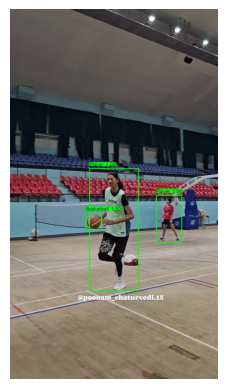

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml

# Path to the image and label file
image_path = '/content/Basketball/Basketball/val/images/Basketball (113).jpg'
label_path = '/content/yolov5/runs/detect/exp/labels/Basketball (113).txt'
yaml_path = '/content/Basketball/Basketball/basketball.yaml'

# Load class names from the YAML file
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

class_names = data['names']  # This should give you the list of class names

# Read the image using OpenCV
img = cv2.imread(image_path)

# Get image dimensions
height, width, _ = img.shape

# Open the label file and read the detection results
with open(label_path, 'r') as f:
    lines = f.readlines()

# Iterate through each detection and draw the bounding box with labels
for line in lines:
    # Parse the label file: class_id, x_center, y_center, width, height, confidence (optional)
    parts = line.strip().split()

    # Ensure there are at least 5 values (class_id, x_center, y_center, width, height)
    if len(parts) < 5:
        continue  # Skip lines that do not have enough data

    class_id = int(parts[0])
    x_center = float(parts[1]) * width  # Convert normalized x_center to pixels
    y_center = float(parts[2]) * height  # Convert normalized y_center to pixels
    box_width = float(parts[3]) * width  # Convert normalized width to pixels
    box_height = float(parts[4]) * height  # Convert normalized height to pixels

    # Check if confidence is available (optional)
    confidence = float(parts[5]) if len(parts) > 5 else 1.0  # Default confidence = 1.0

    # Convert center coordinates and box dimensions to top-left corner coordinates
    x1 = int(x_center - box_width / 2)
    y1 = int(y_center - box_height / 2)
    x2 = int(x_center + box_width / 2)
    y2 = int(y_center + box_height / 2)

    # Draw the bounding box on the image
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)  # Green box

    # Get the class name and create the label
    label = f"{class_names[class_id]} {confidence:.2f}"

    # Set the font and size for the label text
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.5
    font_thickness = 1
    text_size = cv2.getTextSize(label, font, font_scale, font_thickness)[0]
    text_x = x1
    text_y = y1 - 10  # Place the label just above the box

    # Draw the label background and text
    cv2.rectangle(img, (text_x, text_y), (text_x + text_size[0], text_y - text_size[1]), (0, 255, 0), -1)
    cv2.putText(img, label, (text_x, text_y), font, font_scale, (0, 0, 0), font_thickness)

# Convert from BGR (OpenCV format) to RGB (matplotlib format)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the image with bounding boxes and labels
plt.imshow(img_rgb)
plt.axis('off')  # Hide axis
plt.show()